# Lab 1.15 · Optimizing attention

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Why can exact attention use less temporary memory without changing which tokens it can read?

Kiely explains that a straightforward implementation writes the score matrix and the softmax probability matrix, only to read them again in the next operation. **FlashAttention** tiles and fuses the calculation to avoid materializing those full matrices in GPU memory. It still covers the same query–key pairs. **PagedAttention** addresses a different problem by organizing the persistent KV cache into pages. **Sliding-window attention** instead changes which keys each query can see.

In this lab, the reference keeps scores and probabilities for every causal row. You will stream one query at a time over key chunks. For each chunk, track the running maximum score, the sum of exponentials relative to that maximum, and the weighted sum of values on the same scale. Divide the weighted sum by the normalizer after the last chunk. For example, if the running max rises from 2 to 3, multiply both old sums by exp(2 − 3) before adding the new contribution. That rescaling keeps early and late contributions comparable.

For N causal queries the two reference intermediates together contain N(N+1) scalar entries. With chunks of size B, the streamed loop holds at most B scores at once and keeps an accumulator of value width. These are counts for the intermediates shown here. They exclude inputs, outputs and Python overhead and do not measure GPU traffic or speed.

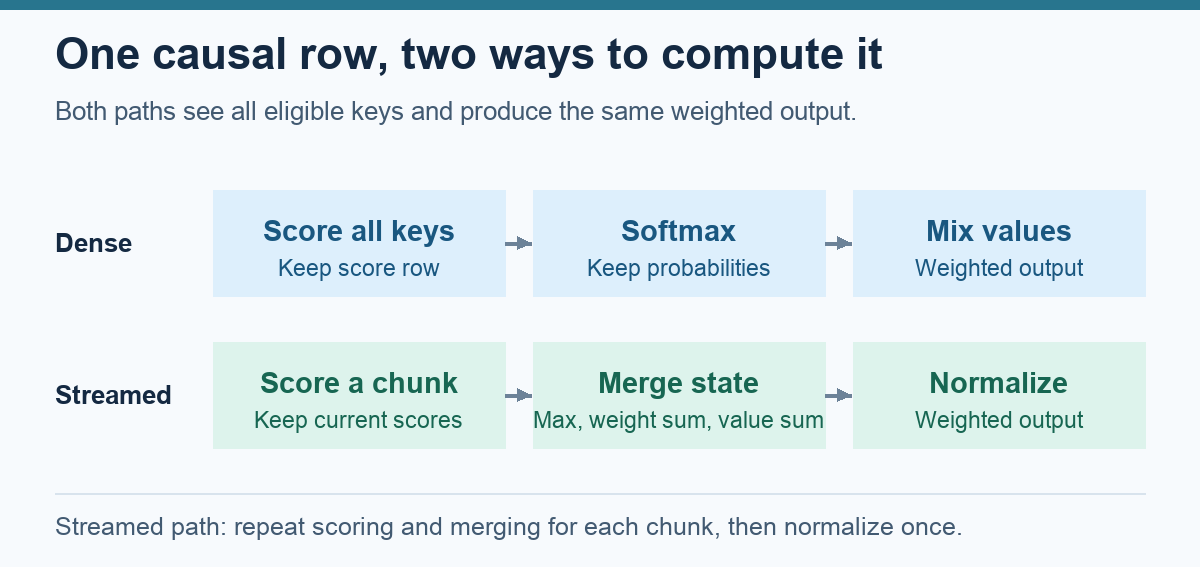

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Merge a chunk | Rebase the existing sums when a higher score appears. | Test large absolute scores and a maximum change and signed, two-component values. |
| 2. Stream causal attention | Process only eligible keys in chunks and normalize once per query. | Match the dense output with different chunk sizes. Then restrict visibility and inspect the change. |

**Reading** · Philip Kiely, *Inference Engineering*, §2.5, pp. 67–69.

In [ ]:
from math import exp, isclose
from random import Random

def score(query, key):
    return sum(a * b for a, b in zip(query, key)) / len(key)**0.5

def dense_attention(queries, keys, values):
    scores = [[score(query, key) for key in keys[:i + 1]]
              for i, query in enumerate(queries)]
    probabilities = []
    for row in scores:
        maximum = max(row)
        weights = [exp(x - maximum) for x in row]
        total = sum(weights)
        probabilities.append([weight / total for weight in weights])
    return [[sum(weight * value[j] for weight, value in zip(row, values))
             for j in range(len(values[0]))] for row in probabilities]

rng = Random(9)
queries = [[rng.uniform(-2, 2) for _ in range(3)] for _ in range(7)]
keys = [[rng.uniform(-2, 2) for _ in range(3)] for _ in queries]
values = [[rng.uniform(-1, 1) for _ in range(2)] for _ in queries]
reference = dense_attention(queries, keys, values)
print("Dense output for last query:", reference[-1])

## Exercise 1. Merge a score chunk

Complete the merge for a nonempty chunk. Find the new maximum. Rescale both old sums by exp(old maximum − new maximum), then add the chunk contributions using exp(score − new maximum). Initial state is negative infinity, zero normalizer, and a zero vector. All scores are finite.

In [ ]:
def merge_chunk(maximum, normalizer, weighted, scores, values):
    return None

In [ ]:
first = merge_chunk(float("-inf"), 0.0, [0.0, 0.0], [998], [[2, -1]])
if first is None:
    print("Complete merge_chunk, then rerun this check.")
else:
    maximum, normalizer, weighted = merge_chunk(*first, [1000], [[4, 3]])
    factor = exp(-2)
    assert maximum == 1000
    assert isclose(normalizer, 1 + factor)
    assert isclose(weighted[0], 4 + 2 * factor)
    assert isclose(weighted[1], 3 - factor)
    print("PASS — rebased normalizer and weighted sum:", normalizer, weighted)

## Exercise 2. Stream one causal row at a time

For query index i, visit keys 0 through i in chunks. Reset the running state for every query. When a window is given, start at max(0, i + 1 − window). Treat block size and window as positive integers. Return one normalized value vector per query.

In [ ]:
def streamed_attention(queries, keys, values, block_size, window=None):
    return None

In [ ]:
if first is None or streamed_attention(queries, keys, values, 2) is None:
    print("Complete both functions, then rerun this check.")
else:
    for block_size in (1, 2, 4, 16):
        output = streamed_attention(queries, keys, values, block_size)
        assert len(output) == len(reference)
        for row, expected in zip(output, reference):
            assert len(row) == len(expected)
            assert all(isclose(a, b, abs_tol=1e-12) for a, b in zip(row, expected))
    local = streamed_attention(queries, keys, values, 2, window=1)
    assert all(isclose(a, b, abs_tol=1e-12) for row, expected in zip(local, values)
               for a, b in zip(row, expected))
    assert any(not isclose(a, b, abs_tol=1e-12) for a, b in zip(local[-1], reference[-1]))
    length = len(queries)
    wide_window = streamed_attention(queries, keys, values, 2, window=length)
    assert all(isclose(a, b, abs_tol=1e-12) for row, expected in zip(wide_window, reference)
               for a, b in zip(row, expected))
    print("Full causal pairs:", sum(range(1, length + 1)))
    print("Pairs with a 3-token window:", sum(min(i + 1, 3) for i in range(length)))
    print("Two dense intermediates, scalar entries:", length * (length + 1))
    print("Maximum chunk scores per query at block size 2:", min(length, 2))
    print("Last output with window 1:", local[-1])
    print("PASS — tiling preserves output within tolerance; limiting visibility can change it")

## Wrap-up

Double sequence length at fixed chunk size. What happens to the full causal pair count and to the maximum number of scores stored for one query? What changes if the window stays fixed? Which quantities would a real GPU benchmark need to measure?

## Optional system exercise · Validating an optimized attention kernel

At fixed head and value widths, streaming keeps the full causal pair count at O(N²) and reduces the temporary score storage in this implementation. A window of width w permits at most Nw pairs and changes the set of visible keys. To compare GPU kernels, report measured time and DRAM traffic at matching shapes, masks, and precision.

Use the dense implementation as a numerical oracle. Name two inputs besides the seeded case you would use to test an optimized version. Include a case that changes the running maximum across chunks and a case with a partial final chunk. Separately specify what you would measure to support a memory-traffic claim.